## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sid Luthra

**Date:** 10/12/26

In [1]:
#Q1:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])
    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])
    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({'x1': X1[0], 'x2': X1[1], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0], 'x2': X2[1], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0], 'x2': X3[1], 'group': 'c'})

    return pd.concat([gdf1, gdf2, gdf3], axis=0)

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}


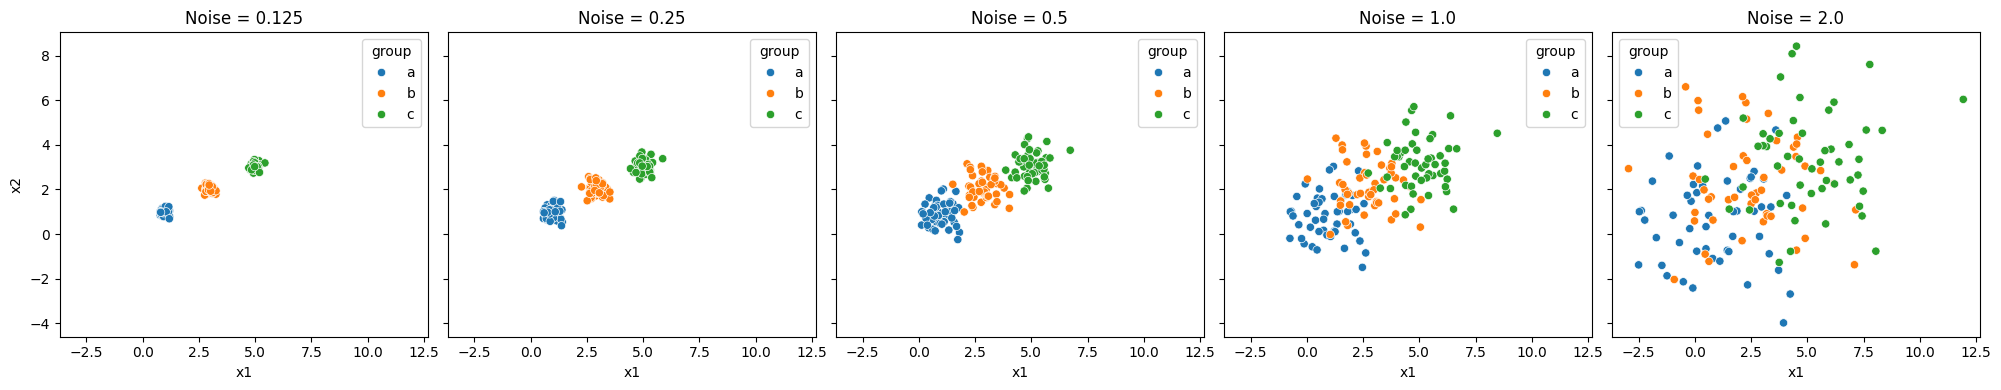

In [2]:
#Q1.2:
fig, axes = plt.subplots(1, 5, figsize=(20, 4),
                         sharex=True, sharey=True)

for ax, (noise, data) in zip(axes, datasets.items()):
    sns.scatterplot(
        data=data, x='x1', y='x2',
        hue='group', ax=ax
    )
    ax.set_title(f"Noise = {noise}")

plt.tight_layout()
plt.show()

At noise levels of 0.125 and 0.25, the three groups form tight,
clearly separated clusters. At 0.5, the groups spread out and begin
to overlap. At 1.0 and 2.0, the overlap becomes substantial, making
the original groups harder to distinguish visually.

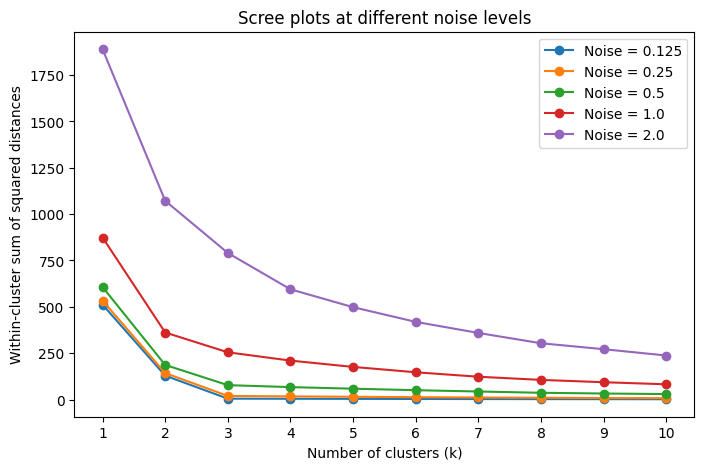

In [3]:
#Q1.3:
ks = range(1, 11)

plt.figure(figsize=(8, 5))

for noise, data in datasets.items():
    inertias = []

    for k in ks:
        model = KMeans(
            n_clusters=k, random_state=100, n_init=10
        )
        model.fit(data[['x1', 'x2']])
        inertias.append(model.inertia_)

    plt.plot(ks, inertias, marker='o', label=f"Noise = {noise}")

plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squared distances")
plt.title("Scree plots at different noise levels")
plt.xticks(list(ks))
plt.legend()
plt.show()

Q1.3:
At low noise, the curves go down steeply until around k = 3 and then they flatten, which makes three clusters a clear choice. When noise increases, the within-cluster sum of squared distances increases. The higher-noise curves decline more slowly, so selecting one k confidently becomes much harder.

Q1.4:
The elbow marks where adding more clusters starts producing smaller improvements. With three separated groups, increasing k from one to three allows each group to have its own center, greatly reducing squared distances. Beyond three, additional centers mostly divide existing groups, so the improvement is small.
With more noise, the groups overlap and extra centers continue to reduce distances, making the elbow less obvious.

In [4]:
df = pd.read_csv("SIPRI Military Expenditure Database.csv")

df = df[df['Year'] == 2020].dropna().copy()

variables = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

print("Number of countries:", len(df))
print(df[variables].dtypes)

Number of countries: 148
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object


Q2.1:
After filtering to 2020 and dropping rows with missing values, 148 countries remain.

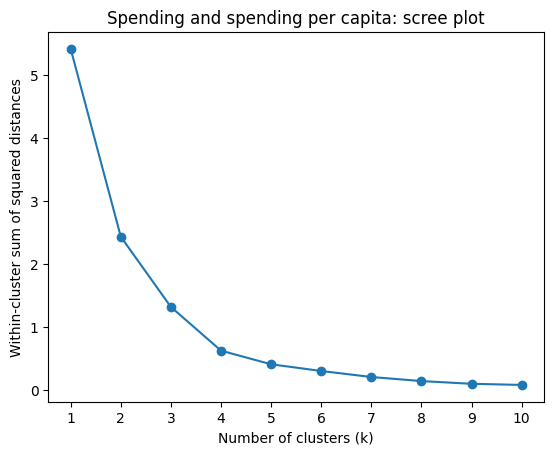

In [5]:
#Q2.2:
spending_cols = [
    'Spending (2020 USD)',
    'Spending per Capita'
]

X_spending = MinMaxScaler().fit_transform(df[spending_cols])

inertias = []

for k in ks:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_spending)
    inertias.append(model.inertia_)

plt.plot(ks, inertias, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squared distances")
plt.title("Spending and spending per capita: scree plot")
plt.xticks(list(ks))
plt.show()

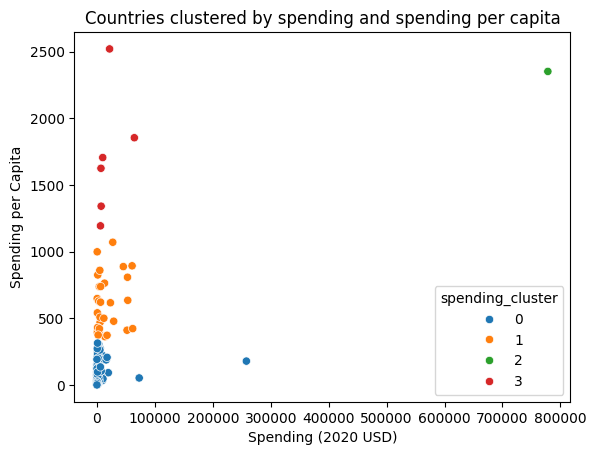

Spending (2020 USD)                               \
                               count           mean           std   
spending_cluster                                                    
0                              111.0    4859.185065  25405.739131   
1                               30.0   17077.591354  20583.053357   
2                                1.0  778397.200000           NaN   
3                                6.0   19443.362047  22861.507114   

                                                                              \
                            min            25%            50%            75%   
spending_cluster                                                               
0                      8.622460     130.010211     382.464677    2297.032353   
1                    405.790494    2294.039665    5857.060906   26296.001003   
2                 778397.200000  778397.200000  778397.200000  778397.200000   
3                   6095.708713    7023.251766    8624.225729   18857.070183   

                                Spending per Capita                           \
                            max               count         mean         std   
spending_cluster                                                               
0                 257973.429834               111.0    80.061470   83.501824   
1                  61712.537169                30.0   607.478618  206.928757   
2                 778397.200000                 1.0  2351.631858         NaN   
3                  64558.400000                 6.0  1706.721916  466.375705   

                                                                      \
                          min          25%          50%          75%   
spending_cluster                                                       
0                    0.580129    14.880549    47.056944   125.387558   
1                  362.467076   422.208252   579.004604   757.328513   
2                 2351.631858  2351.631858  2351.631858  2351.631858   
3                 1193.598730  1412.083201  1665.447478  1817.219993   

                               
                          max  
spending_cluster               
0                  314.201312  
1                 1070.623322  
2                 2351.631858  
3                 2520.398541

,Country,spending_cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [6]:
df['spending_cluster'] = KMeans(
    n_clusters=4, random_state=100, n_init=10
).fit_predict(X_spending)

sns.scatterplot(
    data=df,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='spending_cluster',
    palette='tab10'
)
plt.title("Countries clustered by spending and spending per capita")
plt.show()

display(df.groupby('spending_cluster')[spending_cols].describe())

display(
    df.loc[
        df['Country'] == 'United States of America',
        ['Country', 'spending_cluster'] + spending_cols
    ]
)

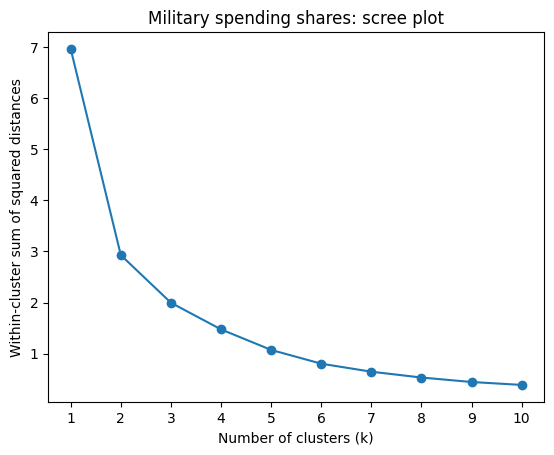

In [7]:
#Q2.3:
percent_cols = [
    'Percent of Government Spending',
    'Percent of GDP'
]

X_percent = MinMaxScaler().fit_transform(df[percent_cols])

inertias = []

for k in ks:
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_percent)
    inertias.append(model.inertia_)

plt.plot(ks, inertias, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster sum of squared distances")
plt.title("Military spending shares: scree plot")
plt.xticks(list(ks))
plt.show()

I selected k = 2 because the largest decrease occurs between one and two clusters, after which the curve declines more gradually.

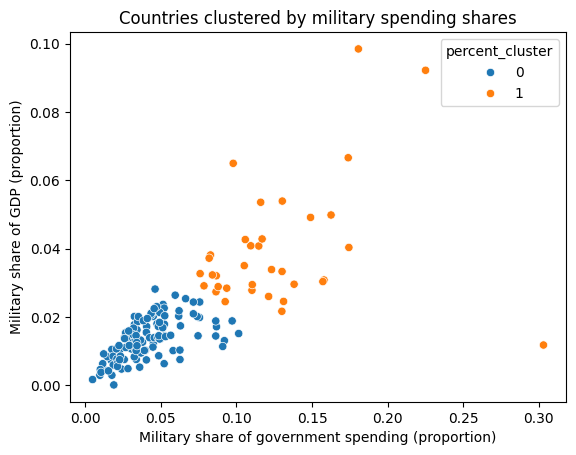

Percent of Government Spending                                \
                                         count      mean       std       min   
percent_cluster                                                                
0                                        113.0  0.041394  0.020681  0.004896   
1                                         35.0  0.126456  0.046209  0.076005   

                                                        Percent of GDP  \
                      25%       50%       75%       max          count   
percent_cluster                                                          
0                0.026783  0.038486  0.051496  0.101501          113.0   
1                0.093093  0.116052  0.143584  0.303027           35.0   

                                                                             \
                     mean       std       min       25%       50%       75%   
percent_cluster                                                               
0                0.013481  0.005966  0.000054  0.009147  0.013631  0.017830   
1                0.039433  0.018179  0.011742  0.028962  0.033281  0.042722   

                           
                      max  
percent_cluster            
0                0.028132  
1                0.098470

,Country,percent_cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,1,0.081976,0.037179


In [8]:
df['percent_cluster'] = KMeans(
    n_clusters=2, random_state=100, n_init=10
).fit_predict(X_percent)

sns.scatterplot(
    data=df,
    x='Percent of Government Spending',
    y='Percent of GDP',
    hue='percent_cluster',
    palette='tab10'
)
plt.xlabel("Military share of government spending (proportion)")
plt.ylabel("Military share of GDP (proportion)")
plt.title("Countries clustered by military spending shares")
plt.show()

display(df.groupby('percent_cluster')[percent_cols].describe())

display(
    df.loc[
        df['Country'] == 'United States of America',
        ['Country', 'percent_cluster'] + percent_cols
    ]
)

In [9]:
#Q2.4:
X_all = MinMaxScaler().fit_transform(df[variables])

df['all_cluster'] = KMeans(
    n_clusters=3, random_state=100, n_init=10
).fit_predict(X_all)

display(df.groupby('all_cluster')[variables].mean())
display(df.groupby('all_cluster').size().rename('Country count'))

display(
    df.loc[
        df['Country'] == 'United States of America',
        ['Country', 'spending_cluster', 'percent_cluster', 'all_cluster']
    ]
)

us_cluster = df.loc[
    df['Country'] == 'United States of America', 'all_cluster'
].iloc[0]

display(df.loc[df['all_cluster'] == us_cluster, ['Country']])

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,7086.472777,196.926833,0.040350,0.013419
1,147964.582042,1875.150751,0.135351,0.062634
2,8786.086602,212.689100,0.122985,0.033492


,Country count
all_cluster,
0,111
1,6
2,31


,Country,spending_cluster,percent_cluster,all_cluster
5540,United States of America,2,1,1


,Country
2582,Israel
2922,Kuwait
4044,Oman
4486,Saudi Arabia
4656,Singapore
5540,United States of America


Q2.5:

K-means determined some useful differences between countries with high military spending amounts and countries that devote large shares of their budgets or economies to the military. The United States stands out most strongly when total spending is included, while other countries stand out more by their spending shares. These patterns help summarize the data, although the groups depend on the variables, normalization, and number of clusters chosen.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [10]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]